In [299]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from scipy.stats import pointbiserialr
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
import warnings

warnings.filterwarnings("ignore")

In [251]:
df = pd.read_csv("./sonar_data.csv", header=None)

In [252]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,51,52,53,54,55,56,57,58,59,60
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,R
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,R
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,R
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,R


In [253]:
df.columns = [f"col_{i}" for i in range(df.shape[1])]

In [254]:
df.columns

Index(['col_0', 'col_1', 'col_2', 'col_3', 'col_4', 'col_5', 'col_6', 'col_7',
       'col_8', 'col_9', 'col_10', 'col_11', 'col_12', 'col_13', 'col_14',
       'col_15', 'col_16', 'col_17', 'col_18', 'col_19', 'col_20', 'col_21',
       'col_22', 'col_23', 'col_24', 'col_25', 'col_26', 'col_27', 'col_28',
       'col_29', 'col_30', 'col_31', 'col_32', 'col_33', 'col_34', 'col_35',
       'col_36', 'col_37', 'col_38', 'col_39', 'col_40', 'col_41', 'col_42',
       'col_43', 'col_44', 'col_45', 'col_46', 'col_47', 'col_48', 'col_49',
       'col_50', 'col_51', 'col_52', 'col_53', 'col_54', 'col_55', 'col_56',
       'col_57', 'col_58', 'col_59', 'col_60'],
      dtype='str')

In [255]:
df.head()

,col_0,col_1,col_2,col_3,col_4,col_5,col_6,col_7,col_8,col_9,...,col_51,col_52,col_53,col_54,col_55,col_56,col_57,col_58,col_59,col_60
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,R
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,R
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,R
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,R
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,R


In [256]:
df.isnull().sum()

col_0     0
col_1     0
col_2     0
col_3     0
col_4     0
         ..
col_56    0
col_57    0
col_58    0
col_59    0
col_60    0
Length: 61, dtype: int64

In [257]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 61 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   col_0   208 non-null    float64
 1   col_1   208 non-null    float64
 2   col_2   208 non-null    float64
 3   col_3   208 non-null    float64
 4   col_4   208 non-null    float64
 5   col_5   208 non-null    float64
 6   col_6   208 non-null    float64
 7   col_7   208 non-null    float64
 8   col_8   208 non-null    float64
 9   col_9   208 non-null    float64
 10  col_10  208 non-null    float64
 11  col_11  208 non-null    float64
 12  col_12  208 non-null    float64
 13  col_13  208 non-null    float64
 14  col_14  208 non-null    float64
 15  col_15  208 non-null    float64
 16  col_16  208 non-null    float64
 17  col_17  208 non-null    float64
 18  col_18  208 non-null    float64
 19  col_19  208 non-null    float64
 20  col_20  208 non-null    float64
 21  col_21  208 non-null    float64
 22  col_22  208 n

In [258]:
df["col_60"].value_counts()

col_60
M    111
R     97
Name: count, dtype: int64

In [259]:
encoder = LabelEncoder()
df["col_60"] = encoder.fit_transform(df["col_60"])

In [260]:
df["col_60"].value_counts()

col_60
0    111
1     97
Name: count, dtype: int64

In [261]:
df.head()

,col_0,col_1,col_2,col_3,col_4,col_5,col_6,col_7,col_8,col_9,...,col_51,col_52,col_53,col_54,col_55,col_56,col_57,col_58,col_59,col_60
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,1
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,1
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,1
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,1
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,1


In [262]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 61 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   col_0   208 non-null    float64
 1   col_1   208 non-null    float64
 2   col_2   208 non-null    float64
 3   col_3   208 non-null    float64
 4   col_4   208 non-null    float64
 5   col_5   208 non-null    float64
 6   col_6   208 non-null    float64
 7   col_7   208 non-null    float64
 8   col_8   208 non-null    float64
 9   col_9   208 non-null    float64
 10  col_10  208 non-null    float64
 11  col_11  208 non-null    float64
 12  col_12  208 non-null    float64
 13  col_13  208 non-null    float64
 14  col_14  208 non-null    float64
 15  col_15  208 non-null    float64
 16  col_16  208 non-null    float64
 17  col_17  208 non-null    float64
 18  col_18  208 non-null    float64
 19  col_19  208 non-null    float64
 20  col_20  208 non-null    float64
 21  col_21  208 non-null    float64
 22  col_22  208 n

<Axes: xlabel='col_0', ylabel='Count'>

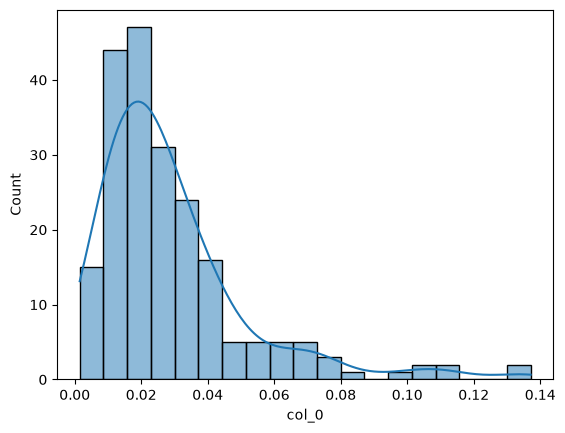

In [263]:
sns.histplot(df["col_0"], kde=True)

In [264]:
df["col_60"].value_counts()

col_60
0    111
1     97
Name: count, dtype: int64

In [265]:
df.columns

Index(['col_0', 'col_1', 'col_2', 'col_3', 'col_4', 'col_5', 'col_6', 'col_7',
       'col_8', 'col_9', 'col_10', 'col_11', 'col_12', 'col_13', 'col_14',
       'col_15', 'col_16', 'col_17', 'col_18', 'col_19', 'col_20', 'col_21',
       'col_22', 'col_23', 'col_24', 'col_25', 'col_26', 'col_27', 'col_28',
       'col_29', 'col_30', 'col_31', 'col_32', 'col_33', 'col_34', 'col_35',
       'col_36', 'col_37', 'col_38', 'col_39', 'col_40', 'col_41', 'col_42',
       'col_43', 'col_44', 'col_45', 'col_46', 'col_47', 'col_48', 'col_49',
       'col_50', 'col_51', 'col_52', 'col_53', 'col_54', 'col_55', 'col_56',
       'col_57', 'col_58', 'col_59', 'col_60'],
      dtype='str')

In [266]:
numeric_cols = ['col_0', 'col_1', 'col_2', 'col_3', 'col_4', 'col_5', 'col_6', 'col_7',
       'col_8', 'col_9', 'col_10', 'col_11', 'col_12', 'col_13', 'col_14',
       'col_15', 'col_16', 'col_17', 'col_18', 'col_19', 'col_20', 'col_21',
       'col_22', 'col_23', 'col_24', 'col_25', 'col_26', 'col_27', 'col_28',
       'col_29', 'col_30', 'col_31', 'col_32', 'col_33', 'col_34', 'col_35',
       'col_36', 'col_37', 'col_38', 'col_39', 'col_40', 'col_41', 'col_42',
       'col_43', 'col_44', 'col_45', 'col_46', 'col_47', 'col_48', 'col_49',
       'col_50', 'col_51', 'col_52', 'col_53', 'col_54', 'col_55', 'col_56',
       'col_57', 'col_58', 'col_59']

correlation = {}

for col in numeric_cols:
  point_biserial_correlation = pointbiserialr(df[col], df["col_60"])
  correlation[col] = {
    "correlation": point_biserial_correlation[0],
    "p_value": point_biserial_correlation[1],
  }

correlation

{'col_0': {'correlation': np.float64(-0.2716941061552171),
  'p_value': np.float64(7.19489971076563e-05)},
 'col_1': {'correlation': np.float64(-0.2312379845733047),
  'p_value': np.float64(0.000777940174576305)},
 'col_2': {'correlation': np.float64(-0.1921947457558873),
  'p_value': np.float64(0.00541677459185159)},
 'col_3': {'correlation': np.float64(-0.25063845884088154),
  'p_value': np.float64(0.0002607819189515216)},
 'col_4': {'correlation': np.float64(-0.22223183509528363),
  'p_value': np.float64(0.0012544689082520748)},
 'col_5': {'correlation': np.float64(-0.13232650383573905),
  'p_value': np.float64(0.05673767736442115)},
 'col_6': {'correlation': np.float64(-0.1147483899048849),
  'p_value': np.float64(0.09885956615500906)},
 'col_7': {'correlation': np.float64(-0.1893142751877843),
  'p_value': np.float64(0.00616853249476273)},
 'col_8': {'correlation': np.float64(-0.32144838619261407),
  'p_value': np.float64(2.1980127140373835e-06)},
 'col_9': {'correlation': np.floa

In [267]:
correlation_df = pd.DataFrame.from_dict(correlation, orient="index")
correlation_df.sort_values(by="correlation", ascending=False, inplace=True)

In [268]:
correlation_df.head()

,correlation,p_value
col_35,0.269151,0.000085
col_34,0.227670,0.000942
col_36,0.209055,0.002442
col_33,0.172010,0.012978
col_30,0.110728,0.111334


<Axes: xlabel='correlation', ylabel='Count'>

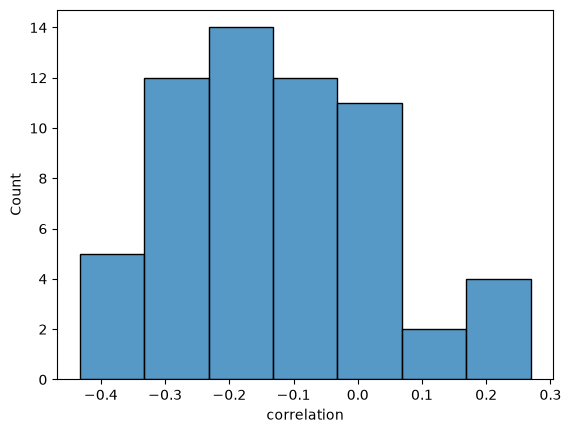

In [269]:
sns.histplot(correlation_df["correlation"])

In [270]:
alpha = 0.05
useful = correlation_df[(correlation_df["p_value"] < alpha) & (abs(correlation_df["correlation"])) > 0.01].copy()

In [271]:
useful

,correlation,p_value
col_35,0.269151,8.453979e-05
col_34,0.227670,9.421519e-04
col_36,0.209055,2.442166e-03
col_33,0.172010,1.297834e-02
col_18,-0.138204,4.650687e-02
col_52,-0.141871,4.094219e-02
col_41,-0.144147,3.777823e-02
col_13,-0.157277,2.328318e-02
col_49,-0.180224,9.189272e-03
col_53,-0.182687,8.262708e-03


In [272]:
useful["abs_correlation"] = useful["correlation"].abs()

In [273]:
useful.sort_values(by='abs_correlation', ascending=False, inplace=True)

In [274]:
useful.index

Index(['col_10', 'col_11', 'col_48', 'col_9', 'col_44', 'col_47', 'col_8',
       'col_12', 'col_45', 'col_46', 'col_50', 'col_51', 'col_43', 'col_0',
       'col_35', 'col_3', 'col_20', 'col_42', 'col_1', 'col_34', 'col_19',
       'col_4', 'col_36', 'col_21', 'col_2', 'col_7', 'col_57', 'col_53',
       'col_49', 'col_33', 'col_13', 'col_41', 'col_52', 'col_18'],
      dtype='str')

In [275]:
selected_features = useful.index
# selected_features_df = df[selected_features]
selected_features_df = df[numeric_cols]

In [276]:
selected_features_df
y = df["col_60"]

In [277]:
selected_features_df.head()

,col_0,col_1,col_2,col_3,col_4,col_5,col_6,col_7,col_8,col_9,...,col_50,col_51,col_52,col_53,col_54,col_55,col_56,col_57,col_58,col_59
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0232,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0125,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0033,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0241,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0156,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094


In [289]:
X_train, X_test, y_train, y_test = train_test_split(selected_features_df, y, test_size=0.1, stratify=y, random_state=42)

In [290]:
pipe = Pipeline([
  ("scaler", StandardScaler()),
  ("model", LogisticRegression(max_iter=1000, random_state=42))
])

param_grid = [
    {
        "model__penalty": ["l2"],
        "model__C": [0.001, 0.01, 0.1, 1, 10, 100],
        "model__class_weight": [None, "balanced"],
    },
    {
        "model__penalty": ["l1"],
        "model__solver": ["liblinear", "saga"],
        "model__C": [0.01, 0.1, 1, 10],
        "model__class_weight": [None, "balanced"],
    },
]

In [291]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_validate(
    pipe,
    selected_features_df,
    y,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "roc_auc": "roc_auc",
        "f1": "f1",
    },
    return_train_score=True,
)

In [301]:
grid = GridSearchCV(
  estimator=pipe,
  param_grid=param_grid,
  cv=cv,
  refit=True
)

In [293]:
grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'model__C': [0.001, 0.01, ...], 'model__class_weight': [None, 'balanced'], 'model__penalty': ['l2']}, {'model__C': [0.01, 0.1, ...], 'model__class_weight': [None, 'balanced'], 'model__penalty': ['l1'], 'model__solver': ['liblinear', 'saga']}]"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example o

In [294]:
grid.best_score_

np.float64(0.765149359886202)

In [295]:
best_pipe = grid.best_estimator_
best_pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](60,)","['col_0','col_1','col_2',...,'col_57','col_58','col_59']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,60
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [296]:
y_pred = best_pipe.predict(X_test)

In [297]:
accuracy_score(y_pred, y_test)

0.8571428571428571

In [298]:
confusion_matrix(y_test, y_pred)

array([[11,  0],
       [ 3,  7]])

In [323]:
input_data = np.asarray((0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,0.6333,0.7060,0.5544,0.5320,0.6479,0.6931,0.6759,0.7551,0.8929,0.8619,0.7974,0.6737,0.4293,0.3648,0.5331,0.2413,0.5070,0.8533,0.6036,0.8514,0.8512,0.5045,0.1862,0.2709,0.4232,0.3043,0.6116,0.6756,0.5375,0.4719,0.4647,0.2587,0.2129,0.2222,0.2111,0.0176,0.1348,0.0744,0.0130,0.0106,0.0033,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078))
input_data

array([0.0262, 0.0582, 0.1099, 0.1083, 0.0974, 0.228 , 0.2431, 0.3771,
       0.5598, 0.6194, 0.6333, 0.706 , 0.5544, 0.532 , 0.6479, 0.6931,
       0.6759, 0.7551, 0.8929, 0.8619, 0.7974, 0.6737, 0.4293, 0.3648,
       0.5331, 0.2413, 0.507 , 0.8533, 0.6036, 0.8514, 0.8512, 0.5045,
       0.1862, 0.2709, 0.4232, 0.3043, 0.6116, 0.6756, 0.5375, 0.4719,
       0.4647, 0.2587, 0.2129, 0.2222, 0.2111, 0.0176, 0.1348, 0.0744,
       0.013 , 0.0106, 0.0033, 0.0232, 0.0166, 0.0095, 0.018 , 0.0244,
       0.0316, 0.0164, 0.0095, 0.0078])

In [328]:
best_pipe.predict(input_data.reshape(1,-1))

array([1])

In [ ]:
df.head()

,col_0,col_1,col_2,col_3,col_4,col_5,col_6,col_7,col_8,col_9,...,col_51,col_52,col_53,col_54,col_55,col_56,col_57,col_58,col_59,col_60
0,0.0200,0.0371,0.0428,0.0207,0.0954,0.0986,0.1539,0.1601,0.3109,0.2111,...,0.0027,0.0065,0.0159,0.0072,0.0167,0.0180,0.0084,0.0090,0.0032,1
1,0.0453,0.0523,0.0843,0.0689,0.1183,0.2583,0.2156,0.3481,0.3337,0.2872,...,0.0084,0.0089,0.0048,0.0094,0.0191,0.0140,0.0049,0.0052,0.0044,1
2,0.0262,0.0582,0.1099,0.1083,0.0974,0.2280,0.2431,0.3771,0.5598,0.6194,...,0.0232,0.0166,0.0095,0.0180,0.0244,0.0316,0.0164,0.0095,0.0078,1
3,0.0100,0.0171,0.0623,0.0205,0.0205,0.0368,0.1098,0.1276,0.0598,0.1264,...,0.0121,0.0036,0.0150,0.0085,0.0073,0.0050,0.0044,0.0040,0.0117,1
4,0.0762,0.0666,0.0481,0.0394,0.0590,0.0649,0.1209,0.2467,0.3564,0.4459,...,0.0031,0.0054,0.0105,0.0110,0.0015,0.0072,0.0048,0.0107,0.0094,1
